In [1]:
%load_ext autoreload
%autoreload 2

from bankingsupportagent.tools.card_tools import fetch_cards, change_card_status

print(fetch_cards("C1002"))
print()
print(change_card_status("C1001", "4821", "freeze"))              # normal freeze
print(change_card_status("C1001", "4821", "freeze"))              # already frozen
print(change_card_status("C1001", "4821", "unfreeze"))            # back to active
print(change_card_status("C1001", "7710", "freeze"))              # Priya's card!
print(change_card_status("C1001", "4111111111111111", "freeze"))  # full card number

Platinum Debit ending 7710 | status: active | international usage: on
Secure Rewards Credit ending 3392 | status: active | international usage: off

Done. The card ending 4821 is now frozen.
Cannot freeze the card ending 4821: it's current status is frozen
Done. The card ending 4821 is now active.
No card ending 7710 was found on this customer's profile
Please give only the last 4 digits of your card. Never share the full card number


In [2]:
from bankingsupportagent.tools.policy_tools import search_policies

print(search_policies.invoke({"query": "freeze card instead of blocking"}))

c:\Users\abhin\OneDrive\Desktop\AbhinavJain\Projects\BankingSupportAgent\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 103/103 [00:00<00:00, 3551.51it/s]


[Source: 03_debit_and_credit_card_terms.pdf, page 2]
credit limit. The Bank may review and change the credit limit, and will inform the cardholder of any
reduction in advance. A limit increase is offered only with the cardholder's explicit consent.
5. Lost, Stolen or Compromised Cards
5.1 Blocking a card
If a card is lost, stolen, or the cardholder suspects that card details have been compromised, the
cardholder must block the card immediately using any of the following channels, available 24x7:
  SecureBank mobile app: Cards > Block Card (instant).
 SecureBank support chat in the app or on the website.
 Toll-free helpline 1800-000-1234 (24x7), or +91-22-4000-1234 from outside India.
 SMS 'BLOCK ' to 56767 from the registered mobile number.
 Any SecureBank branch during working hours.
Blocking is permanent and cannot be reversed. The Bank will send an SMS and email confirmation with a
reference number immediately after blocking. Any liability for transactions after the card is rep

In [3]:
from bankingsupportagent.tools.card_tools import file_dispute

print(file_dispute("C1002", "2026-09-18", "XYZ DIGITAL", "I did not make this payment"))
print(file_dispute("C1002", "2026-09-18", "XYZ DIGITAL", "Trying again"))
print(file_dispute("C1001", "2026-09-18", "XYZ DIGITAL", "Rahul tries Priya's transaction"))
print(file_dispute("C1002", "2026-09-01", "SALARY", "Disputing a credit"))

Dispute raised for CARD ONLINE - XYZ DIGITAL SERVICES (Rs. 5,000.00) on 2026-09-18. Reference number: DSP-000011. Disputes are resolved within 30 working days.
This transaction is already under dispute (reference DSP-000011).
No debit from 'XYZ DIGITAL' on 2026-09-18 was found on this customer's accounts.
No debit from 'SALARY' on 2026-09-01 was found on this customer's accounts.


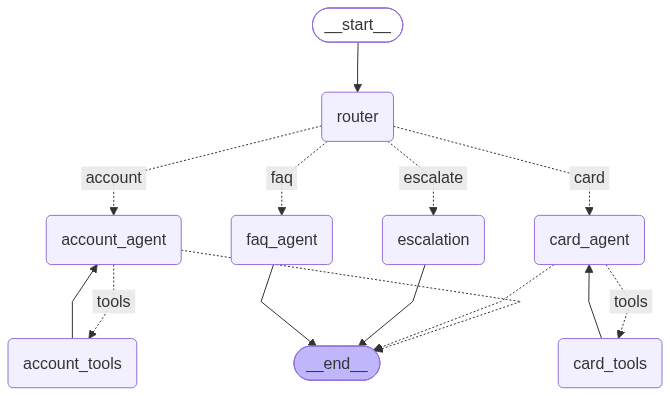

In [2]:
%load_ext autoreload
%autoreload 2

from IPython.display import Image, display
from langgraph.types import Command
from bankingsupportagent.graph import build_graph
from bankingsupportagent.tools.card_tools import fetch_card_status

graph = build_graph()
display(Image(graph.get_graph().draw_mermaid_png()))


def show(label, result):
    print(f"Q: {label}")
    if "__interrupt__" in result:
        print(f"⏸  PAUSED → {result['__interrupt__'][0].value['message']}\n")
        return
    print(f"Route: {result.get('route')}")
    print(f"A: {result['messages'][-1].content}\n")


def chat(message, thread_id, customer_id=None):
    inputs = {"messages": message}
    if customer_id:
        inputs["customer_id"] = customer_id
    result = graph.invoke(inputs, config={"configurable": {"thread_id": thread_id}})
    show(message, result)


def confirm(approved, thread_id):
    result = graph.invoke(
        Command(resume={"approved": approved}),
        config={"configurable": {"thread_id": thread_id}},
    )
    show(f"[Customer clicks {'YES' if approved else 'NO'}]", result)

In [3]:
chat("I misplaced my card ending 4821. Should I block it or can I just freeze it?", "r1", customer_id="C1001")
chat("Ok, freeze it please", "r1")
print("DB status:", fetch_card_status("C1001", "4821"), "\n")
chat("Found it! Unfreeze my card", "r1")
print("DB status:", fetch_card_status("C1001", "4821"))

Q: I misplaced my card ending 4821. Should I block it or can I just freeze it?
Route: card
A: Freezing a card temporarily stops any new transactions, but you can unfreeze it later if you find the card.  
Blocking a card is permanent – it’s used when the card is lost, stolen, or you suspect it’s been compromised, and it can’t be undone.

If you think you might locate the card, freezing is a good first step. If you’re sure it’s lost or could be used by someone else, you should block it.

Would you like me to **freeze** the card ending 4821, or would you prefer to **block** it?

Q: Ok, freeze it please
Route: card
A: Your card ending 4821 has been frozen. Let me know if you need anything else—unfreeze it, block it, or anything else.

DB status: frozen 

Q: Found it! Unfreeze my card
Route: card
A: Your card ending 4821 is now active again. If you need any further help, just let me know!

DB status: active


In [4]:
chat("My card ending 4821 was stolen, block it now", "r2", customer_id="C1001")
confirm(False, "r2")
print("DB status:", fetch_card_status("C1001", "4821"))

Q: My card ending 4821 was stolen, block it now
⏸  PAUSED → Blocking the card ending 4821 is permanant and cannot be undone. Do you want to continue?

Q: [Customer clicks NO]
Route: card
A: I understand. I can place a temporary freeze on the card ending 4821 instead. Would you like me to do that?

DB status: active


In [5]:
chat("My card ending 4821 was stolen, block it now", "r3", customer_id="C1001")
confirm(True, "r3")
print("DB status:", fetch_card_status("C1001", "4821"))

Q: My card ending 4821 was stolen, block it now
⏸  PAUSED → Blocking the card ending 4821 is permanant and cannot be undone. Do you want to continue?

Q: [Customer clicks YES]
Route: card
A: Your card ending 4821 has been permanently blocked. If you need a replacement, you can request one in the app. Let me know if there’s anything else I can help with.

DB status: blocked


In [6]:
chat("There's a Rs 5000 charge from XYZ Digital Services that I don't recognise", "p1", customer_id="C1002")
chat("Yes, that's the one. Please raise a dispute.", "p1")
chat("Block my card ending 7710", "r4", customer_id="C1001")

Q: There's a Rs 5000 charge from XYZ Digital Services that I don't recognise
Route: card
A: I see a Rs 5,000 debit on 2026‑09‑18 from **XYZ Digital Services** on the card ending **4321**. Would you like me to raise a dispute for this transaction?

Q: Yes, that's the one. Please raise a dispute.
Route: card
A: Your dispute has been filed. The reference number is **DSP-000011**. You should hear back within 30 working days. Let me know if you need anything else.

Q: Block my card ending 7710
Route: card
A: I’m sorry—I don’t see a card ending 7710 on your profile. The only card I have for you is a Classic Debit ending 4821, which is already **blocked**.

Let me know if you’d like help with a different card or anything else.



In [7]:
from bankingsupportagent.tools.account_tools import fetch_transactions
print(fetch_transactions("C1002", 2))

2026-09-25 | SIP - MUTUAL FUND | Debit Rs. 10,000.00 | XXXX4321
2026-09-18 | CARD ONLINE - XYZ DIGITAL SERVICES | Debit Rs. 5,000.00 | XXXX4321
